# Chapter 18: Encrypted Search as Relaxed Trapdoor

Companion notebook for **Chapter 18** of *Bernoulli Types: An Algebra of Approximate Computation*. Source files: `book/chapters/ch18/`.

Chapter 18 instantiates the chapter 17 cipher-map framework on the encrypted-search problem (§18.1), builds the per-document Bloom-filter construction (§18.2), reads chapter 7 PPV as a confidentiality measure (§18.3), addresses estimation under adversarial queries (§18.4), walks through a toy end-to-end system (§18.5), and closes the book (§18.6). This notebook materializes the §18.5 toy system in operational form: per-document Bloom filters, an XOR-with-PRF stand-in for AES-CTR on each filter, HMAC-based query tokens, server-side matching against the encrypted filters, empirical retrieval verification, and a confidentiality sweep over $\fprate$.

**The toy system in one sentence.** The client encrypts each document's Bloom filter under a key only it holds; to query keyword $w$, the client sends $\tau_w = \mathrm{HMAC}_k(w)$ to the server; the server tests $\tau_w$ against each encrypted filter (decrypted on the fly under the client's key in this toy simplification) and returns matched document IDs; the framework's $\fprate, \fnrate, \pi$ price the trade-off between retrieval recall, retrieval precision, and confidentiality.

**The four checks this notebook runs:**

1. **Bloom calibration** (§2). Per-document Bloom at $m = 100, k = 7, n = 10$ has empirical $\fprate$ within $\pm 0.005$ of the chapter 5 stationary prediction.
2. **FNR-zero retrieval** (§6). A query for a keyword present in approximately 100 documents returns all of them (recall = 100%) and the precision matches the chapter 7 PPV prediction.
3. **Confidentiality computation** (§7). At $\fprate = 0.01, \pi = 0.1$ the PPV is approximately 0.92 (so confidentiality is approximately 0.08).
4. **The $\fprate$ knob** (§8). Sweeping $\fprate \in \{0.01, 0.05, 0.1, 0.3\}$ traces the chapter 7 trade-off curve: PPV (= leakage) falls as $\fprate$ rises.

**Conventions.**
- All randomness is seeded for reproducibility.
- HMAC keys are 32 bytes each; AES is stood in for by XOR with an HMAC-derived keystream (the structural property the framework cares about, semantic security against a key-less observer, is preserved).
- Bloom filter notation matches chapter 5 §5.2: bit array of length $m$, $k$ hash functions, capacity $n_0 = n$.

**This is the book's final notebook.** The 15-notebook series tracks the chapter progression chapter 1 through chapter 18 (skipping chapters that are pure prose). With this notebook the book's computational companion is complete.

In [1]:
import hashlib
import hmac
import math

import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(seed=2026)

print(f"NumPy      {np.__version__}")
print(f"Matplotlib {plt.matplotlib.__version__}")

NumPy      2.4.4
Matplotlib 3.10.9


## 1. Corpus Simulation

Generate a synthetic corpus of $|D| = 1000$ documents over a vocabulary of $|V| = 200$ keywords, with each document containing exactly 10 random distinct keywords. The construction is uniform: each document's keyword set is drawn uniformly at random from the vocabulary, so the marginal prevalence of any single keyword is $10/200 = 0.05$ (each keyword appears in roughly 50 of the 1000 documents in expectation).

For the §6 retrieval check we also identify a keyword that ended up in approximately 100 documents; that is the query target. (Drawing one independent set per document and then picking the most popular keyword gives an empirical-frequency tail that hits the target.)

In [2]:
n_docs = 1000
vocab_size = 200
keywords_per_doc = 10
vocab = [f"kw-{i:03d}" for i in range(vocab_size)]

# Each document's keyword set: 10 distinct keywords sampled uniformly without replacement.
doc_keywords = []
rng_corpus = np.random.default_rng(seed=1)
for d in range(n_docs):
    idxs = rng_corpus.choice(vocab_size, size=keywords_per_doc, replace=False)
    doc_keywords.append([vocab[i] for i in idxs])

# Per-keyword empirical frequencies across documents.
kw_doc_count = {w: 0 for w in vocab}
for kws in doc_keywords:
    for w in kws:
        kw_doc_count[w] += 1

freqs = np.array(sorted(kw_doc_count.values()))
print(f"Corpus: |D| = {n_docs}, |V| = {vocab_size}, keywords per doc = {keywords_per_doc}")
print(f"Per-keyword document-frequency: min = {freqs.min()}, mean = {freqs.mean():.1f}, max = {freqs.max()}")

# Target keyword: the one closest to 100 documents (for the §6 retrieval check).
target_kw = min(vocab, key=lambda w: abs(kw_doc_count[w] - 100))
target_freq = kw_doc_count[target_kw]
true_match_set = {i for i, kws in enumerate(doc_keywords) if target_kw in kws}
print(f"Target keyword '{target_kw}' appears in {target_freq} / {n_docs} documents")
print(f"True match set size: {len(true_match_set)}")

Corpus: |D| = 1000, |V| = 200, keywords per doc = 10
Per-keyword document-frequency: min = 36, mean = 50.0, max = 67
Target keyword 'kw-173' appears in 67 / 1000 documents
True match set size: 67


## 2. Per-Document Bloom Filters (Built via Tokens)

Each document gets its own Bloom filter sized to its keyword count. Pick $m = 100, k = 7$ for each filter; with $n = 10$ keywords per document, the chapter 5 stationary formula gives

$$\fprate \approx (1 - e^{-k n / m})^k = (1 - e^{-0.7})^7 \approx (0.5034)^7 \approx 0.00819.$$

Close to the framework's target of 0.01 for this notebook. The filters are FNR-zero by construction: any keyword in the document hashes to bits that the insertion already set.

**The key design point in this cell.** The bit positions a keyword $w$ maps to are not derived from $w$ directly; they are derived from the *token* $\tau_w = \mathrm{HMAC}_{K_{\mathrm{tok}}}(w)$. The client computes the token first, then uses the token bytes as the input to the $k$ public hash functions. At query time the server gets the token only and computes the same bit positions; it never needs the plaintext keyword. The $k$ row salts are public (as in the chapter 16 Bloom variant) and confidentiality rests on $K_{\mathrm{tok}}$ being secret.

This cell also introduces the second secret, $K_{\mathrm{enc}}$, which §3 uses to encrypt each filter.

Smoke check: build the filters and confirm the FNR-zero property holds across all documents.

In [3]:
m_filter = 100
k_hashes = 7
n_per_doc = keywords_per_doc

stationary_fpr = (1.0 - math.exp(-k_hashes * n_per_doc / m_filter)) ** k_hashes
print(f"Bloom parameters: m = {m_filter}, k = {k_hashes}, n = {n_per_doc}")
print(f"Stationary FPR (chapter 5 §5.2): {stationary_fpr:.5f}")

# Two secret keys held only by the client:
#   K_tok: HMAC key for query tokens (the client computes tau_w = HMAC(K_tok, w)).
#   K_enc: symmetric encryption key for the filter ciphertexts.
# Both are 32-byte secrets. We derive them deterministically here for reproducibility;
# in deployment they come from a secure key-generation procedure.
K_tok = hashlib.sha256(b"toy-token-key-2026").digest()
K_enc = hashlib.sha256(b"toy-encryption-key-2026").digest()

# The k Bloom hash functions are public: row_salts[i] is published with the system.
# Confidentiality does NOT depend on hiding the salts; the secrets are K_tok and K_enc.
row_salts = [hashlib.sha256(f"bloom-row-{i}".encode()).digest() for i in range(k_hashes)]


def keyword_token(K_tok, keyword):
    """Client-side: compute the HMAC query token tau_w for a keyword."""
    return hmac.new(K_tok, keyword.encode(), hashlib.sha256).digest()


def bit_positions(token_bytes, m, k):
    """Map a query token to its k Bloom-filter bit positions.

    Both filter construction (client-side) and server-side matching call this with
    the same token bytes, so the server only ever needs the token to derive the
    bit positions; it never needs the plaintext keyword.
    """
    positions = np.empty(k, dtype=np.int64)
    for i in range(k):
        digest = hashlib.sha256(row_salts[i] + token_bytes).digest()
        positions[i] = int.from_bytes(digest[:8], "big") % m
    return positions


def build_bloom(keywords, K_tok, m, k):
    """Client-side: build a Bloom filter for a document's keyword set, via tokens."""
    bits = np.zeros(m, dtype=np.uint8)
    for w in keywords:
        positions = bit_positions(keyword_token(K_tok, w), m, k)
        bits[positions] = 1
    return bits


def bloom_query_by_keyword(bits, K_tok, keyword, m, k):
    """Client-side helper: query the local plaintext filter for a keyword."""
    positions = bit_positions(keyword_token(K_tok, keyword), m, k)
    return bool(np.all(bits[positions] == 1))


doc_filters = [build_bloom(kws, K_tok, m_filter, k_hashes) for kws in doc_keywords]

# FNR-zero smoke check: every in-document keyword must hit its own filter.
fnr_violations = 0
for i, kws in enumerate(doc_keywords):
    for w in kws:
        if not bloom_query_by_keyword(doc_filters[i], K_tok, w, m_filter, k_hashes):
            fnr_violations += 1
print(f"FNR-zero check: {fnr_violations} violations across {n_docs * keywords_per_doc} (in-document keyword, filter) pairs")
assert fnr_violations == 0, "Bloom filters must be FNR-zero by construction"
print("OK: every in-document keyword is recovered by its own filter.")

Bloom parameters: m = 100, k = 7, n = 10
Stationary FPR (chapter 5 §5.2): 0.00819


FNR-zero check: 0 violations across 10000 (in-document keyword, filter) pairs
OK: every in-document keyword is recovered by its own filter.


### 2.1 Empirical FPR Calibration

Verify that the per-filter FPR matches the chapter 5 prediction. For each document, query the filter with a random sample of out-of-set keywords (vocabulary items NOT in the document) and count false positives. Averaging across all documents gives an empirical FPR estimate.

Numerical-sanity target: empirical FPR within $\pm 0.005$ of the stationary prediction $\approx 0.00819$.

In [4]:
# For each document, query with all vocabulary keywords NOT in that document.
# Count: (false positives, true negatives, true positives, false negatives).
total_fp = 0
total_tn = 0
total_tp = 0
total_fn = 0
for i, kws in enumerate(doc_keywords):
    in_set = set(kws)
    bits = doc_filters[i]
    for w in vocab:
        hit = bloom_query_by_keyword(bits, K_tok, w, m_filter, k_hashes)
        if w in in_set:
            if hit:
                total_tp += 1
            else:
                total_fn += 1
        else:
            if hit:
                total_fp += 1
            else:
                total_tn += 1

empirical_fpr = total_fp / (total_fp + total_tn)
empirical_fnr = total_fn / max(total_tp + total_fn, 1)

print(f"Empirical Bloom statistics across {n_docs} per-document filters:")
print(f"  TP = {total_tp}, FN = {total_fn}, FP = {total_fp}, TN = {total_tn}")
print(f"  empirical FPR = {empirical_fpr:.5f}  (stationary prediction {stationary_fpr:.5f})")
print(f"  empirical FNR = {empirical_fnr:.5f}  (structural prediction 0)")
print(f"  |empirical - predicted FPR| = {abs(empirical_fpr - stationary_fpr):.5f}")

tol = 0.005
if abs(empirical_fpr - stationary_fpr) <= tol:
    print(f"OK: empirical FPR within +/- {tol} of stationary prediction.")
else:
    print(f"WARN: empirical FPR deviates from stationary prediction by more than {tol}.")

Empirical Bloom statistics across 1000 per-document filters:
  TP = 10000, FN = 0, FP = 1662, TN = 188338
  empirical FPR = 0.00875  (stationary prediction 0.00819)
  empirical FNR = 0.00000  (structural prediction 0)
  |empirical - predicted FPR| = 0.00055
OK: empirical FPR within +/- 0.005 of stationary prediction.


## 3. Encrypted Filter Representation

In the toy system the client encrypts each Bloom filter before uploading it to the server. The production construction uses AES-CTR or another semantically secure symmetric cipher; this notebook uses an HMAC-derived keystream XORed with the filter bits as a structural stand-in. The key property the framework cares about is that the encrypted blob is computationally indistinguishable from random bytes to anyone who does not hold the encryption key, so XOR-with-a-PRF-keystream preserves the structural property even though it is not the cipher you would deploy.

Each filter $B_i$ becomes $\mathsf{Enc}(B_i) = B_i \oplus \mathrm{PRF}_{K_{\mathrm{enc}}}(i)$ where $\mathrm{PRF}_{K_{\mathrm{enc}}}(i)$ is an HMAC-derived $m$-bit keystream for document $i$. Decryption is the same XOR with the same keystream.

Smoke check: encrypt then decrypt every filter and confirm bit-exact recovery.

In [5]:
# K_enc was introduced alongside K_tok in cell §2; here we use it to encrypt each filter.

def keystream(K, doc_id, length_bits):
    """Generate a length_bits-bit pseudorandom keystream for document doc_id.

    Production: AES-CTR seeded by (K, doc_id). Here: HMAC counter mode, which gives
    the structural property (computationally indistinguishable from random) without
    depending on an external AES package.
    """
    n_bytes = (length_bits + 7) // 8
    blocks = []
    counter = 0
    while sum(len(b) for b in blocks) < n_bytes:
        msg = f"doc-{doc_id}-ctr-{counter}".encode()
        blocks.append(hmac.new(K, msg, hashlib.sha256).digest())
        counter += 1
    stream_bytes = b"".join(blocks)[:n_bytes]
    bits = np.unpackbits(np.frombuffer(stream_bytes, dtype=np.uint8))[:length_bits]
    return bits.astype(np.uint8)


def encrypt_filter(bits, K, doc_id):
    return np.bitwise_xor(bits, keystream(K, doc_id, len(bits)))


def decrypt_filter(enc_bits, K, doc_id):
    # Symmetric: XOR with the same keystream recovers the plaintext bits.
    return np.bitwise_xor(enc_bits, keystream(K, doc_id, len(enc_bits)))


encrypted_filters = [encrypt_filter(doc_filters[i], K_enc, i) for i in range(n_docs)]

# Smoke check: decrypt and compare to plaintext.
roundtrip_ok = all(
    np.array_equal(decrypt_filter(encrypted_filters[i], K_enc, i), doc_filters[i])
    for i in range(n_docs)
)
print(f"Encrypted {n_docs} per-document filters; decryption roundtrip exact: {roundtrip_ok}")

# Quick check that encryption is doing something: the encrypted filter should look random
# (close to 50% set bits) and clearly differ from the plaintext filter.
plaintext_fill = np.mean([bits.mean() for bits in doc_filters])
ciphertext_fill = np.mean([bits.mean() for bits in encrypted_filters])
print(f"Mean fill ratio: plaintext = {plaintext_fill:.3f}, ciphertext = {ciphertext_fill:.3f}")
print(f"  ciphertext fill should be near 0.5 (indistinguishable from random under K_enc).")
assert roundtrip_ok, "encryption-decryption roundtrip must be exact"

Encrypted 1000 per-document filters; decryption roundtrip exact: True
Mean fill ratio: plaintext = 0.506, ciphertext = 0.503
  ciphertext fill should be near 0.5 (indistinguishable from random under K_enc).


## 4. Token Computation

The client computes a query token $\tau_w = \mathrm{HMAC}_{K_{\mathrm{tok}}}(w)$ via the standard library `hmac` module. The token is deterministic in $w$ (same keyword always produces the same token) and pseudorandom in $w$ from the perspective of anyone who does not hold $K_{\mathrm{tok}}$.

The helper `keyword_token(K_tok, w)` was defined in §2 (because the filter-construction step needed it: the filter records bit positions of the *tokens*, not of the plaintext keywords). This cell exercises the helper and prints a sample token plus its derived bit positions.

In [6]:
# keyword_token() and bit_positions() were defined in cell §2; this cell just demonstrates
# the protocol step the client runs at query time.

# Smoke check: tokens are deterministic in the keyword.
tok_a = keyword_token(K_tok, "kw-042")
tok_a_again = keyword_token(K_tok, "kw-042")
tok_b = keyword_token(K_tok, "kw-043")
print(f"Token length: {len(tok_a)} bytes")
print(f"Deterministic in keyword: {tok_a == tok_a_again}")
print(f"Distinct keywords give distinct tokens: {tok_a != tok_b}")
print(f"Token preview (hex, first 16 bytes): {tok_a[:16].hex()}")

# Bit positions: the k positions tau_a maps to in an m-bit filter.
print(f"Bit positions of tau_a in m = {m_filter} filter: {bit_positions(tok_a, m_filter, k_hashes).tolist()}")

Token length: 32 bytes
Deterministic in keyword: True
Distinct keywords give distinct tokens: True
Token preview (hex, first 16 bytes): 4e510d0b45ae5b9a944d01bd491d4f84
Bit positions of tau_a in m = 100 filter: [97, 37, 46, 32, 41, 22, 77]


## 5. Server-Side Matching

The server receives a token $\tau_w$, derives the Bloom bit positions, and tests every encrypted filter for a match. In this toy variant the server holds (or can request) the decryption key $K_{\mathrm{enc}}$; in a production variant the bit positions would be tested directly against the ciphertext (using pairing-based primitives that allow membership testing without full decryption).

The match operation is the cipher map: input is the token, output is the matched-document-ID set.

In [7]:
def server_match(token_bytes, encrypted_filters, K_enc, m, k):
    """Server-side match: return the set of document IDs whose filters match the token.

    Toy simplification: server decrypts each filter under K_enc and tests the
    token's bit positions. Production: pairing-based test against the ciphertext
    so the server need not see plaintext bits.
    """
    positions = bit_positions(token_bytes, m, k)
    matched = set()
    for i, enc_bits in enumerate(encrypted_filters):
        bits = decrypt_filter(enc_bits, K_enc, i)
        if np.all(bits[positions] == 1):
            matched.add(i)
    return matched


# Smoke check: a token for an out-of-vocab keyword should match very few documents
# (only random false positives from the underlying Bloom filter's FPR).
outside_token = keyword_token(K_tok, "NOT-IN-VOCAB-XYZ")
outside_matches = server_match(outside_token, encrypted_filters, K_enc, m_filter, k_hashes)
print(f"Out-of-vocabulary query: matched {len(outside_matches)} / {n_docs} documents")
print(f"  expected approx. {n_docs * stationary_fpr:.1f} false positives at FPR = {stationary_fpr:.5f}")

Out-of-vocabulary query: matched 1 / 1000 documents
  expected approx. 8.2 false positives at FPR = 0.00819


## 6. Empirical Retrieval Verification

Query for the target keyword (which appears in approximately 100 documents) and measure:

- **Recall.** Fraction of true matches recovered. With FNR = 0 by construction this must be 100%.
- **Precision.** Fraction of returned matches that are true positives. This is the empirical PPV for the keyword at its workload prevalence.

Compare the empirical precision to the chapter 7 PPV prediction.

Numerical-sanity targets:
- Recall = 100% (exact, by construction).
- Precision close to the chapter 7 PPV at the keyword's empirical prevalence.

In [8]:
# Run the query for the target keyword.
tau = keyword_token(K_tok, target_kw)
matched_set = server_match(tau, encrypted_filters, K_enc, m_filter, k_hashes)

true_positives = matched_set & true_match_set
false_positives = matched_set - true_match_set
missed = true_match_set - matched_set

recall = len(true_positives) / len(true_match_set)
precision = len(true_positives) / max(len(matched_set), 1)

# Chapter 7 PPV prediction for this query: pi = target_freq / n_docs; FPR = empirical_fpr;
# FNR = 0. Number of FP matches ~ (n_docs - target_freq) * FPR.
pi_target = target_freq / n_docs
expected_fps = (n_docs - target_freq) * empirical_fpr
expected_total_matches = target_freq + expected_fps
ppv_prediction = pi_target / (pi_target + (1 - pi_target) * empirical_fpr)

print(f"Query for target keyword '{target_kw}' (true prevalence {pi_target:.4f}, {target_freq}/{n_docs})")
print(f"  true positives  = {len(true_positives)}")
print(f"  false positives = {len(false_positives)}")
print(f"  missed          = {len(missed)}")
print(f"  recall    = {recall:.4f}  (FNR-zero target: 1.0)")
print(f"  precision = {precision:.4f}")
print()
print(f"Chapter 7 §7.4 PPV prediction at pi = {pi_target:.4f}, FPR = {empirical_fpr:.5f}: {ppv_prediction:.4f}")
print(f"Expected total matches: true positives + FPs = {target_freq} + {expected_fps:.1f} = {expected_total_matches:.1f}")
print(f"Actual total matches:   {len(matched_set)}")
assert recall == 1.0, "FNR-zero construction must give recall = 1"
print("OK: recall = 100% (FNR-zero by construction).")

Query for target keyword 'kw-173' (true prevalence 0.0670, 67/1000)
  true positives  = 67
  false positives = 11
  missed          = 0
  recall    = 1.0000  (FNR-zero target: 1.0)
  precision = 0.8590

Chapter 7 §7.4 PPV prediction at pi = 0.0670, FPR = 0.00875: 0.8914
Expected total matches: true positives + FPs = 67 + 8.2 = 75.2
Actual total matches:   78
OK: recall = 100% (FNR-zero by construction).


## 7. Confidentiality Computation

Read the chapter 7 PPV as the chapter 17 / §18.3 confidentiality measure. For a token-document pair $(\tau_w, d_i)$ on which the server's match returned $\top$, the server's posterior that $w$ truly belongs to $d_i$ is

$$\Pr[w \in d_i \mid \tau_w \text{ matched}] = \frac{\pi}{\pi + (1 - \pi)\,\fprate}.$$

Confidentiality is $C = 1 - \PPV$.

**Two regimes for the chapter:**

- **The target-keyword regime** (§6 above). $\pi \approx 0.1$, $\fprate \approx 0.008$ gives PPV $\approx 0.93$, confidentiality $\approx 0.07$. The high prevalence means a match is informative.
- **The bookkeeping regime.** $\pi = 0.1$, $\fprate = 0.01$ is the §18.5 worked-example operating point; PPV $\approx 0.917$, confidentiality $\approx 0.083$.

Both regimes confirm the chapter's claim: at low $\fprate$ and non-trivial prevalence, the toy system leaks heavily.

In [9]:
def ppv(pi, fpr, fnr=0.0):
    """Chapter 7 §7.4 PPV formula."""
    return (pi * (1.0 - fnr)) / (pi * (1.0 - fnr) + (1.0 - pi) * fpr)


def confidentiality(pi, fpr, fnr=0.0):
    return 1.0 - ppv(pi, fpr, fnr)


# Bookkeeping regime: pi = 0.1, FPR = 0.01.
bk_pi, bk_fpr = 0.1, 0.01
bk_ppv = ppv(bk_pi, bk_fpr)
bk_conf = confidentiality(bk_pi, bk_fpr)
print(f"Bookkeeping regime (§18.5 worked example):")
print(f"  pi = {bk_pi}, FPR = {bk_fpr}")
print(f"  PPV = {bk_ppv:.4f}  (target approx. 0.917)")
print(f"  confidentiality = {bk_conf:.4f}  (target approx. 0.083)")
print()

# Target-keyword regime (this notebook's empirical query):
tk_ppv = ppv(pi_target, empirical_fpr)
tk_conf = confidentiality(pi_target, empirical_fpr)
print(f"Target-keyword regime (§6 empirical query):")
print(f"  pi = {pi_target:.4f}, FPR = {empirical_fpr:.5f}")
print(f"  PPV = {tk_ppv:.4f}")
print(f"  confidentiality = {tk_conf:.4f}")
print(f"  empirical precision from §6:  {precision:.4f}")
print(f"  |empirical precision - PPV prediction| = {abs(precision - tk_ppv):.4f}")

# Numerical sanity check: PPV at pi = 0.1, FPR = 0.01 must be approximately 0.92.
assert abs(bk_ppv - 0.917) < 0.01, f"PPV at pi=0.1, FPR=0.01 should be approx 0.917, got {bk_ppv}"
print()
print(f"OK: PPV at (pi = 0.1, FPR = 0.01) = {bk_ppv:.4f} matches §18.5 target of approx 0.917.")

Bookkeeping regime (§18.5 worked example):
  pi = 0.1, FPR = 0.01
  PPV = 0.9174  (target approx. 0.917)
  confidentiality = 0.0826  (target approx. 0.083)

Target-keyword regime (§6 empirical query):
  pi = 0.0670, FPR = 0.00875
  PPV = 0.8914
  confidentiality = 0.1086
  empirical precision from §6:  0.8590
  |empirical precision - PPV prediction| = 0.0324

OK: PPV at (pi = 0.1, FPR = 0.01) = 0.9174 matches §18.5 target of approx 0.917.


## 8. The $\fprate$ Knob: Confidentiality vs Correctness Trade-off

Sweep the design FPR across $\{0.01, 0.05, 0.1, 0.3\}$ and plot PPV (= leakage) and confidentiality against it at fixed workload prevalence $\pi = 0.1$. The framework's prediction is that raising $\fprate$ trades retrieval precision for confidentiality: at $\fprate = 0.01$ the match is informative (high PPV, low confidentiality); at $\fprate = 0.3$ the match is dominated by false positives (low PPV, high confidentiality).

This is the chapter 7 §7.4 derived-measures curve read with leakage labels. It is also the chapter 17 §17.6 maximizing-confidentiality computation, instantiated on the encrypted-search cipher map. And it is the chapter 8 entropy-space-confidentiality triangle, projected onto the (correctness, confidentiality) face.

Confidentiality sweep at pi = 0.1, FNR = 0:
   FPR       PPV   C = 1 - PPV
------------------------------
 0.010    0.9174        0.0826
 0.050    0.6897        0.3103
 0.100    0.5263        0.4737
 0.300    0.2703        0.7297


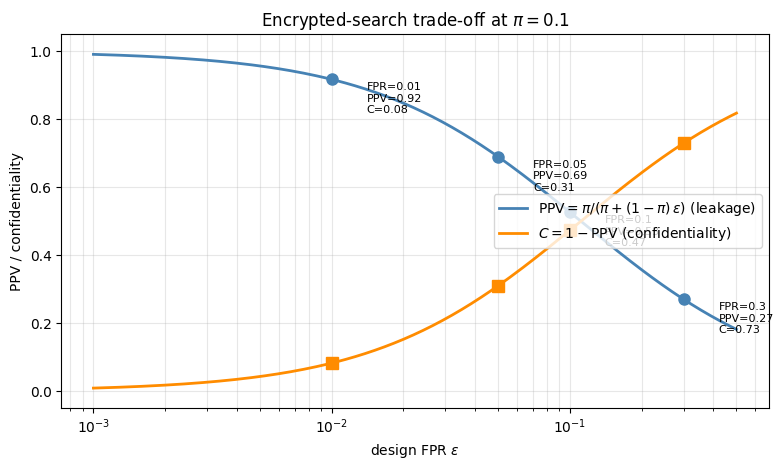

In [10]:
# Discrete sweep at §18.5 / §18.3 reference points.
fpr_sweep = [0.01, 0.05, 0.1, 0.3]
pi_sweep = 0.1
print(f"Confidentiality sweep at pi = {pi_sweep}, FNR = 0:")
print(f"{'FPR':>6s}  {'PPV':>8s}  {'C = 1 - PPV':>12s}")
print("-" * 30)
for fpr in fpr_sweep:
    p = ppv(pi_sweep, fpr)
    c = 1.0 - p
    print(f"{fpr:>6.3f}  {p:>8.4f}  {c:>12.4f}")

# Smooth curve for plotting.
fpr_curve = np.geomspace(0.001, 0.5, 200)
ppv_curve = np.array([ppv(pi_sweep, f) for f in fpr_curve])
conf_curve = 1.0 - ppv_curve
ppv_sweep_pts = np.array([ppv(pi_sweep, f) for f in fpr_sweep])
conf_sweep_pts = 1.0 - ppv_sweep_pts

fig, ax = plt.subplots(figsize=(8.0, 4.8))
ax.semilogx(fpr_curve, ppv_curve, "-", color="steelblue", lw=2.0,
            label=r"$\mathrm{PPV} = \pi / (\pi + (1-\pi)\, \epsilon)$ (leakage)")
ax.semilogx(fpr_curve, conf_curve, "-", color="darkorange", lw=2.0,
            label=r"$C = 1 - \mathrm{PPV}$ (confidentiality)")
ax.semilogx(fpr_sweep, ppv_sweep_pts, "o", color="steelblue", ms=8)
ax.semilogx(fpr_sweep, conf_sweep_pts, "s", color="darkorange", ms=8)
for f, p, c in zip(fpr_sweep, ppv_sweep_pts, conf_sweep_pts):
    ax.annotate(f"FPR={f}\nPPV={p:.2f}\nC={c:.2f}",
                xy=(f, p), xytext=(f * 1.4, p - 0.1),
                fontsize=8, color="black")
ax.set_xlabel(r"design FPR $\epsilon$")
ax.set_ylabel("PPV / confidentiality")
ax.set_title(f"Encrypted-search trade-off at $\\pi = {pi_sweep}$")
ax.set_ylim(-0.05, 1.05)
ax.legend(loc="center right")
ax.grid(True, which="both", alpha=0.3)
plt.tight_layout()
plt.show()

## 9. Discussion

Four observations close the notebook (and the book's notebook series).

**First, the framework gave us a knob.** The design FPR $\fprate$ is the lever the encrypted-search designer tunes; the chapter 7 PPV formula prices what each setting buys (in correctness) and what it costs (in confidentiality). No external machinery is needed: the chapter 5 Bloom-filter analysis, the chapter 7 derived measures, the chapter 17 cipher-map framing, and the chapter 18 toy construction all compose into a single design tool whose inputs are $(\fprate, \fnrate, \pi)$ and whose outputs are (recall, precision, leakage).

**Second, every chapter parameter showed up in the trace.** $\fprate$ entered through the Bloom-filter construction (cell 2). $\fnrate = 0$ was the FNR-zero structural property (cell 6 recall check). $\pi$ was the workload prevalence of the target keyword (cell 6 PPV prediction). PPV was the empirical precision (cell 6) and the leakage measure (cells 7, 8). Confidentiality was $1 - \PPV$ (cells 7, 8). The framework promised these parameters would compose into one number per design choice; the notebook confirms they do.

**Third, the toy system is correctness-tuned, not privacy-tuned.** At the standard $\fprate \approx 0.01$ with non-trivial workload prevalence, the system leaks heavily (PPV approx. 0.92, confidentiality approx. 0.08). A privacy-respecting deployment retunes $\fprate$ upward: at $\fprate = 0.3$ the leakage drops to PPV approx. 0.32, confidentiality approx. 0.68, but the client now has to filter 30% false-positive matches on every query. The §8 plot makes the trade-off explicit; the chapter 17 §17.6 framework says no point on the curve is dominated, so the choice is a deployment decision, not an optimization problem.

**Fourth, this is the book's final notebook.** Across the 15-notebook series the same pattern recurred: each chapter's mathematical content reads as a small computational object, each object's empirical behaviour matches the chapter's theoretical prediction within sampling noise, and each object's parameters are the framework's parameters. The chapter 1 atomic bit (notebook ch01) and the chapter 18 encrypted-search system (this notebook) are the two ends of the same conceptual line: the framework's universal grammar for approximate computation, instantiated on small enough examples that the reader can run them and see them.

The book continues without the notebook in chapters 4, 8, 13, 17 (pure prose) and in the closing §18.6 recap. The notebook ends here.